# UrbanSound8K classification with 1D convolutions

Compare time, frequency and combined convolutional architectures on mel spectrograms. Put `UrbanSound8K.csv` and audio folders `fold1` through `fold10` inside `archive-2/`. Install NumPy, pandas, PyTorch, torchaudio, soundfile, scikit-learn, Matplotlib and seaborn. Set `URBANSOUND_ROOT` to the dataset directory if it is stored elsewhere. The dataset is not included in this repository; see [UrbanSound8K](https://www.kaggle.com/datasets/chrisfilo/urbansound8k) for attribution and license terms.

The original random clip split could place related recordings in both training and evaluation. This version trains on folds 1–8, chooses a model on fold 9, then evaluates that model once on fold 10. The results below were generated on the full dataset using a Kaggle GPU. This single held-out fold is not a substitute for the dataset’s recommended ten-fold cross-validation.

**Data:** [UrbanSound8K](https://www.kaggle.com/datasets/chrisfilo/urbansound8k). Put `UrbanSound8K.csv` and `fold1` through `fold10` in `archive-2/`, or set `URBANSOUND_ROOT`.

In [1]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchaudio
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report


In [2]:
DEVICE = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(42)
np.random.seed(42)
SAMPLE_RATE = 22050
N_MELS = 64
MAX_LEN = 173
NUM_CLASSES = 10


In [3]:
import soundfile as sf

class UrbanSoundDataset(Dataset):
    def __init__(self, csv_file, audio_dir):
        self.df = pd.read_csv(csv_file)
        self.audio_dir = audio_dir

        self.mel = torchaudio.transforms.MelSpectrogram(
            sample_rate=SAMPLE_RATE,
            n_mels=N_MELS
        )
        self.amplitude_to_db = torchaudio.transforms.AmplitudeToDB()

    def __len__(self):
        return len(self.df)

    def _pad_or_crop(self, spec):
        if spec.shape[1] < MAX_LEN:
            pad = MAX_LEN - spec.shape[1]
            spec = F.pad(spec, (0, pad))
        else:
            spec = spec[:, :MAX_LEN]
        return spec

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        path = os.path.join(
            self.audio_dir,
            f"fold{row.fold}",
            row.slice_file_name
        )

        waveform, sr = sf.read(path)   # ← ВАЖНО
        if waveform.ndim > 1:
            waveform = waveform.mean(axis=1)

        waveform = torch.tensor(waveform, dtype=torch.float32).unsqueeze(0)

        if sr != SAMPLE_RATE:
            waveform = torchaudio.functional.resample(
                waveform, sr, SAMPLE_RATE
            )

        spec = self.mel(waveform)
        spec = self.amplitude_to_db(spec)
        spec = spec.squeeze(0)
        spec = self._pad_or_crop(spec)

        label = row.classID
        return spec, label


In [4]:
class ConvTime(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv1d(N_MELS, 128, kernel_size=5, padding=2)
        self.pool1 = nn.MaxPool1d(2)

        self.conv2 = nn.Conv1d(128, 256, kernel_size=5, padding=2)
        self.pool2 = nn.AdaptiveAvgPool1d(1)

        self.fc = nn.Linear(256, NUM_CLASSES)

    def forward(self, x):
        # x: (B, freq, time)
        x = F.relu(self.conv1(x))
        x = self.pool1(x)

        x = F.relu(self.conv2(x))
        x = self.pool2(x)

        x = x.squeeze(-1)
        return self.fc(x)


In [5]:
class ConvFreq(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv1d(MAX_LEN, 128, kernel_size=3, padding=1)
        self.pool1 = nn.MaxPool1d(2)

        self.conv2 = nn.Conv1d(128, 256, kernel_size=3, padding=1)
        self.pool2 = nn.AdaptiveMaxPool1d(1)

        self.fc = nn.Linear(256, NUM_CLASSES)

    def forward(self, x):
        # x: (B, freq, time) → (B, time, freq)
        x = x.transpose(1, 2)

        x = F.relu(self.conv1(x))
        x = self.pool1(x)

        x = F.relu(self.conv2(x))
        x = self.pool2(x)

        x = x.squeeze(-1)
        return self.fc(x)


In [6]:
class ConvTimeFreq(nn.Module):
    def __init__(self):
        super().__init__()

        self.freq_conv = nn.Conv1d(MAX_LEN, 128, kernel_size=3, padding=1)
        self.time_conv = nn.Conv1d(128, 256, kernel_size=5, padding=2)

        self.pool = nn.AdaptiveAvgPool1d(1)
        self.fc = nn.Linear(256, NUM_CLASSES)

    def forward(self, x):
        x = x.transpose(1, 2)
        x = F.relu(self.freq_conv(x))

        x = F.relu(self.time_conv(x))
        x = self.pool(x)

        x = x.squeeze(-1)
        return self.fc(x)


In [7]:
def train_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0

    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)

        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)


In [8]:
def eval_model(model, loader):
    model.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for x, y in loader:
            x = x.to(DEVICE)
            out = model(x)
            preds = out.argmax(dim=1).cpu()

            y_true.extend(y.tolist())
            y_pred.extend(preds.tolist())

    return classification_report(y_true, y_pred, labels=list(range(NUM_CLASSES)), output_dict=True, zero_division=0)


In [9]:
data_root = os.environ.get("URBANSOUND_ROOT", "archive-2")
dataset = UrbanSoundDataset(
    csv_file=os.path.join(data_root, "UrbanSound8K.csv"),
    audio_dir=data_root
)
# UrbanSound8K provides folds designed to keep related source recordings together.
folds = dataset.df["fold"]
train_idx = np.flatnonzero(folds.isin(range(1, 9)).to_numpy())
val_idx = np.flatnonzero((folds == 9).to_numpy())
test_idx = np.flatnonzero((folds == 10).to_numpy())
if min(len(train_idx), len(val_idx), len(test_idx)) == 0:
    raise ValueError("Expected nonempty UrbanSound8K folds 1–8, 9, and 10.")
train_loader = DataLoader(torch.utils.data.Subset(dataset, train_idx), batch_size=32, shuffle=True)
val_loader = DataLoader(torch.utils.data.Subset(dataset, val_idx), batch_size=32)
test_loader = DataLoader(torch.utils.data.Subset(dataset, test_idx), batch_size=32)
print(f"Train: {len(train_idx)}; validation: {len(val_idx)}; test: {len(test_idx)}")

Train: 7079; validation: 816; test: 837


In [10]:
def train_and_evaluate(model, name, epochs=10):
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.CrossEntropyLoss()

    for epoch in range(1, epochs + 1):
        train_epoch(model, train_loader, optimizer, criterion)

    report = eval_model(model, val_loader)

    return {
        "model": name,
        "accuracy": report["accuracy"],
        "macro_f1": report["macro avg"]["f1-score"],
        "weighted_f1": report["weighted avg"]["f1-score"],
        "per_class": report
    }



In [11]:
model_time = ConvTime()
model_freq = ConvFreq()
class ConvFreqTime(nn.Module):
    def __init__(self):
        super().__init__()
        self.freq = nn.Conv1d(MAX_LEN, 128, 3, padding=1)
        self.time = nn.Conv1d(128, 256, 5, padding=2)
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.fc = nn.Linear(256, NUM_CLASSES)

    def forward(self, x):
        x = x.transpose(1, 2)
        x = F.relu(self.freq(x))
        x = F.relu(self.time(x))
        x = self.pool(x)
        return self.fc(x.squeeze(-1))

class ConvParallel(nn.Module):
    def __init__(self):
        super().__init__()

        self.time_conv = nn.Sequential(
            nn.Conv1d(N_MELS, 128, 5, padding=2),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1)
        )

        self.freq_conv = nn.Sequential(
            nn.Conv1d(MAX_LEN, 128, 3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1)
        )

        self.fc = nn.Linear(256, NUM_CLASSES)

    def forward(self, x):
        t = self.time_conv(x).squeeze(-1)
        f = self.freq_conv(x.transpose(1, 2)).squeeze(-1)
        return self.fc(torch.cat([t, f], dim=1))



In [12]:
results = []
model_freq_time = ConvFreqTime()
model_parallel = ConvParallel()
for model, name in [
    (model_time, "ConvTime"),
    (model_freq, "ConvFreq"),
    (model_freq_time, "ConvFreq→Time"),
    (model_parallel, "Parallel Time+Freq")
]:
    print(f"\nTraining {name}")
    res = train_and_evaluate(model, name)
    results.append(res)

# Select one architecture on validation; only this model is evaluated on fold 10.
best_name = max(results, key=lambda result: result["macro_f1"])["model"]
best_model = {"ConvTime": model_time, "ConvFreq": model_freq,
              "ConvFreq→Time": model_freq_time, "Parallel Time+Freq": model_parallel}[best_name]
print(f"Selected on validation: {best_name}")
print("Held-out test report:")
print(pd.DataFrame(eval_model(best_model, test_loader)).T)


Training ConvTime



Training ConvFreq



Training ConvFreq→Time



Training Parallel Time+Freq


Selected on validation: ConvTime
Held-out test report:


              precision    recall  f1-score    support
0              0.750000  0.810000  0.778846  100.00000
1              0.848485  0.848485  0.848485   33.00000
2              0.395349  0.680000  0.500000  100.00000
3              0.833333  0.550000  0.662651  100.00000
4              0.758621  0.660000  0.705882  100.00000
5              0.847458  0.537634  0.657895   93.00000
6              0.568627  0.906250  0.698795   32.00000
7              0.849315  0.645833  0.733728   96.00000
8              0.495327  0.638554  0.557895   83.00000
9              0.641975  0.520000  0.574586  100.00000
accuracy       0.649940  0.649940  0.649940    0.64994
macro avg      0.698849  0.679676  0.671876  837.00000
weighted avg   0.699622  0.649940  0.657688  837.00000


In [13]:
summary = pd.DataFrame([
    {
        "Model": r["model"],
        "Accuracy": r["accuracy"],
        "Macro F1": r["macro_f1"],
        "Weighted F1": r["weighted_f1"]
    }
    for r in results
])

print("Validation results (fold 9):")
summary


Validation results (fold 9):


,Model,Accuracy,Macro F1,Weighted F1
0,ConvTime,0.606618,0.635401,0.595410
1,ConvFreq,0.519608,0.550388,0.518991
2,ConvFreq→Time,0.487745,0.508845,0.479202
3,Parallel Time+Freq,0.560049,0.588363,0.548929


In [14]:
class_tables = {}

for r in results:
    df = pd.DataFrame(r["per_class"]).T
    class_tables[r["model"]] = df.loc[
        [str(i) for i in range(10)], ["f1-score"]
    ].rename(columns={"f1-score": r["model"]})

pd.concat(class_tables.values(), axis=1)


,ConvTime,ConvFreq,ConvFreq→Time,Parallel Time+Freq
0,0.315068,0.313953,0.262500,0.256410
1,0.852459,0.592593,0.596491,0.793103
2,0.527132,0.457143,0.541667,0.556777
3,0.654321,0.460870,0.466102,0.593548
4,0.425532,0.482412,0.387387,0.395722
5,0.691824,0.748538,0.643216,0.578125
6,0.842105,0.866667,0.740741,0.800000
7,0.700508,0.456140,0.491803,0.662921
8,0.736364,0.575000,0.567568,0.723005
9,0.608696,0.550562,0.390977,0.524017


In [15]:
import torch
import numpy as np
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

def get_predictions(model, loader):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for x, y in loader:
            x = x.to(DEVICE)
            outputs = model(x)
            preds = torch.argmax(outputs, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(y.numpy())

    return np.array(all_labels), np.array(all_preds)


In [16]:
labels, preds = get_predictions(best_model, test_loader)

cm = confusion_matrix(labels, preds, labels=list(range(NUM_CLASSES)))

print("Confusion matrix shape:", cm.shape)


Confusion matrix shape: (10, 10)


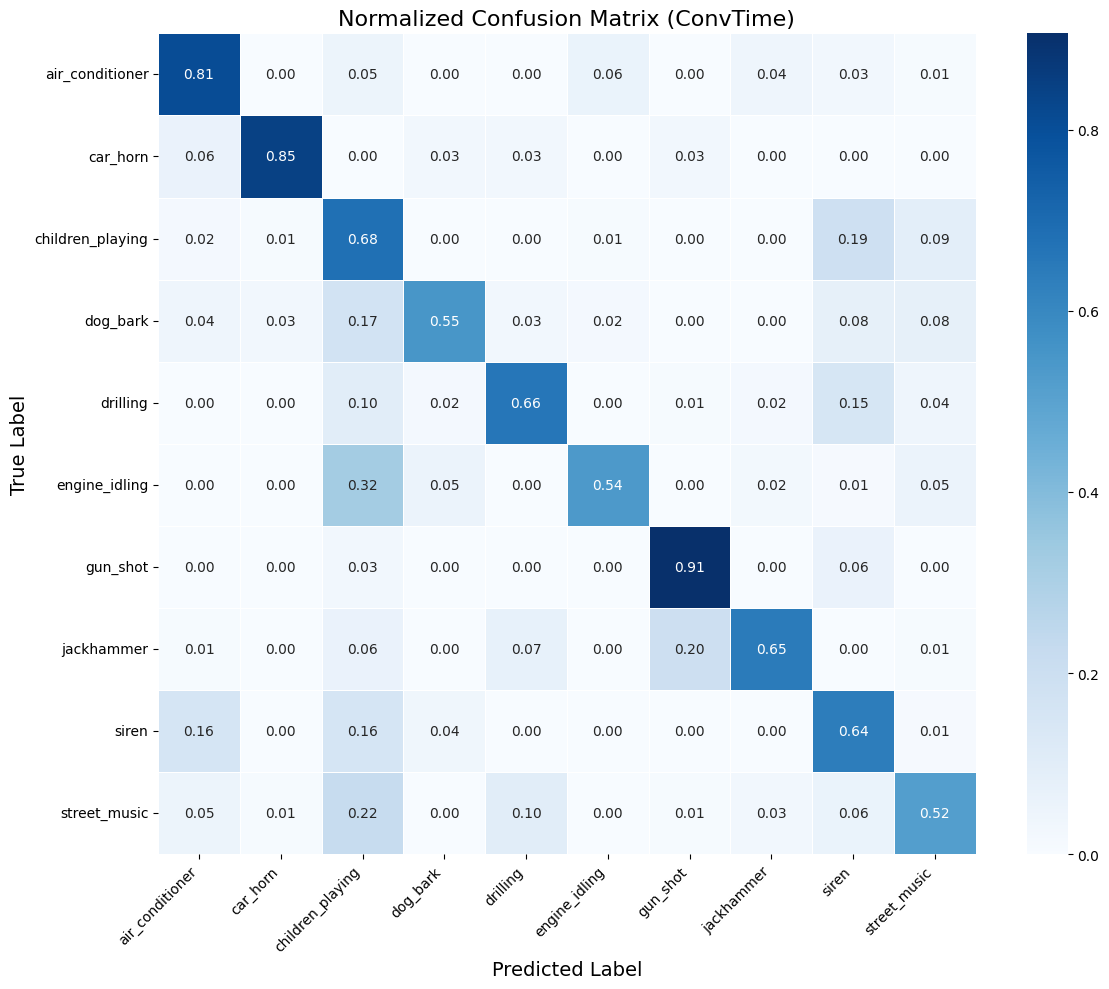

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import numpy as np

# Получаем предсказания
labels, preds = get_predictions(best_model, test_loader)

cm = confusion_matrix(labels, preds, labels=list(range(NUM_CLASSES)))

# Нормализация (по строкам)
cm_norm = np.divide(cm, cm.sum(axis=1, keepdims=True), out=np.zeros_like(cm, dtype=float), where=cm.sum(axis=1, keepdims=True) != 0)

class_names = [
    "air_conditioner",
    "car_horn",
    "children_playing",
    "dog_bark",
    "drilling",
    "engine_idling",
    "gun_shot",
    "jackhammer",
    "siren",
    "street_music"
]

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=True,
    linewidths=0.5
)

plt.title(f"Normalized Confusion Matrix ({best_name})", fontsize=16)
plt.ylabel("True Label", fontsize=14)
plt.xlabel("Predicted Label", fontsize=14)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


Model selection uses fold 9. The held-out fold 10 report and confusion matrix describe only the selected architecture; results from one fold are not a full cross-validation estimate.